# Viagens a serviço — análise dos gastos públicos

**Autor:** Diego Nogueira | **Fonte:** recorte de seis meses de 2025 fornecido pelo professor.

Este notebook executa a etapa Gold após `0_criar_banco.py`, `1_extrair.py` e
`2_transformar.py`. As saídas são calculadas no PostgreSQL; não há resultados simulados.

## Definições de negócio

- Custo líquido da viagem = diárias + passagens + outros gastos − devoluções.
- Duração inclui a data inicial e a final: `(data_fim - data_inicio) + 1`.
  O indicador representa o período informado e deve ser lido junto à situação da viagem.
- Órgão responsável pela viagem usa `nome_orgao_superior`; órgão pagador usa
  `nome_orgao_pagador`. São perguntas e universos financeiros diferentes.
- Destino usa a combinação completa de localidades em `destinos`: uma viagem
  multidestino é um itinerário, e seu custo não é atribuído integralmente a cada cidade.
- Valores ausentes permanecem nulos: somas e médias SQL os ignoram. Rejeições são
  auditadas em `data/quality/`. As conclusões se restringem aos dados aceitos na Silver.
- Duplicatas de pagamentos/passagens são identificadas pela linha completa do CSV,
  incluindo campos não projetados na Silver. Eventos legítimos inteiramente idênticos
  permanecem indistinguíveis sem identificador próprio fornecido pela fonte.


In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib

matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from IPython.display import display, Markdown
from sqlalchemy import create_engine, URL, text

ROOT = Path.cwd()
if not (ROOT / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from config import parametros_banco
from banco import conectar

p = parametros_banco()
engine = create_engine(
    URL.create(
        "postgresql+psycopg",
        username=p["user"],
        password=p["password"],
        host=p["host"],
        port=p["port"],
        database=p["dbname"],
    )
)
plt.style.use("seaborn-v0_8-whitegrid")
pd.options.display.max_colwidth = None
pd.options.display.float_format = lambda valor: (
    f"{valor:,.2f}".replace(",", "_").replace(".", ",").replace("_", ".")
)


def consultar(sql):
    with engine.connect() as conexao:
        return pd.read_sql_query(text(sql), conexao)


def grafico(df, categoria, valor, titulo, eixo, arquivo):
    if df.empty:
        raise ValueError("Consulta sem dados: " + titulo)
    dados = df.copy()
    marcadores = (
        dados[categoria]
        .astype(str)
        .str.strip()
        .str.casefold()
        .isin({"inválido", "não informado", "sigiloso"})
    )
    cores = ["#9A9A9A" if marcador else "#176B87" for marcador in marcadores]
    dados[categoria] = (
        dados[categoria]
        .astype(str)
        .map(lambda s: s if len(s) <= 100 else s[:97] + "...")
        .str.wrap(45)
    )
    fig, ax = plt.subplots(figsize=(12, max(4, len(dados) * 0.65)))
    ax.barh(
        range(len(dados)),
        dados[valor].astype(float),
        color=cores,
        height=0.45 if len(dados) == 1 else 0.7,
    )
    ax.set_yticks(range(len(dados)), dados[categoria])
    ax.invert_yaxis()
    if len(dados) == 1:
        ax.set_ylim(1, -1)
    rotulos = {
        "nome_orgao_superior": "Órgão superior",
        "destinos": "Itinerário",
        "id_viagem": "Identificador da viagem",
        "tipo_pagamento": "Tipo de pagamento",
        "meio_transporte": "Meio de transporte",
        "uf_destino": "UF de destino",
    }
    ax.set(title=titulo, xlabel=eixo, ylabel=rotulos.get(categoria, categoria))
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, pos: f"{x:,.0f}".replace(",", "."))
    )
    legenda = [
        Patch(
            color="#176B87", label="Categorias informadas" if marcadores.any() else eixo
        )
    ]
    if marcadores.any():
        legenda.append(
            Patch(color="#9A9A9A", label="Marcador de informação não identificada")
        )
    fig.legend(
        handles=legenda, loc="lower center", frameon=False, bbox_to_anchor=(0.5, 0)
    )
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    pasta = ROOT / "reports" / "figures"
    pasta.mkdir(parents=True, exist_ok=True)
    fig.savefig(pasta / arquivo, dpi=150, bbox_inches="tight")
    plt.show()


resultados = {}

In [2]:
def apresentar_destinos(df):
    # Apenas a apresentação é abreviada; o resultado completo permanece no JSON.
    if df.empty:
        raise ValueError('Consulta de destinos sem dados')

    def moeda(valor):
        return f'R$ {float(valor):,.2f}'.replace(',', '_').replace('.', ',').replace('_', '.')

    def resumo(texto):
        localidades = list(dict.fromkeys(item.strip() for item in texto.split(',')))
        return ', '.join(localidades[:3]) + (', outras localidades' if len(localidades) > 3 else '')

    rotulos = [f'Itinerário {i}' for i in range(1, len(df) + 1)]
    display(pd.DataFrame({
        'Referência no gráfico': rotulos,
        'Localidades (resumo)': df['destinos'].map(resumo).tolist(),
        'Viagens': df['viagens'].astype(int).tolist(),
        'Custo médio por viagem': df['custo_medio'].map(moeda).tolist(),
    }))
    if df['viagens'].eq(1).all():
        nota = 'Cada grupo contém uma única viagem: a média coincide com o custo dessa viagem.'
    else:
        nota = 'Leia as médias junto à quantidade de viagens de cada grupo na tabela.'
    display(Markdown('**Como interpretar:** ' + nota +
        ' O ranking compara itinerários completos, sem estimar o custo típico de cada cidade. '
        'As listas integrais estão em [resultados.json](reports/resultados.json), na seção `p2`.'))
    fig, ax = plt.subplots(figsize=(12, 5))
    valores = df['custo_medio'].astype(float)
    barras = ax.barh(rotulos, valores, color='#176B87', height=.55)
    ax.invert_yaxis()
    ax.set(title='Três itinerários completos com maior custo médio por viagem',
        xlabel='Custo líquido médio por viagem (R$)', ylabel='Itinerário (ver tabela)')
    ax.set_xlim(0, max(float(valores.max()), 1) * 1.35)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:,.0f}'.replace(',', '.')))
    ax.bar_label(barras, labels=[moeda(v) for v in valores], padding=8, fontsize=11)
    fig.legend(handles=[Patch(color='#176B87', label='Custo líquido médio do itinerário')],
        loc='lower center', bbox_to_anchor=(.5, .07), frameon=False)
    fig.text(.5, .025, nota, ha='center', fontsize=10)
    fig.tight_layout(rect=(0, .16, 1, 1))
    fig.savefig(ROOT / 'reports' / 'figures' / 'p2.png', dpi=150, bbox_inches='tight')
    plt.show()


## Qualidade e cobertura da análise
A contagem permite confrontar Raw, Silver e registros rejeitados. Nenhum dado pessoal de viajante é exibido nas saídas.

In [3]:
contagens = []
for camada in ("raw", "silver"):
    for tabela in ("viagem", "pagamento", "passagem", "trecho"):
        nome = f"{camada}_{tabela}"
        qtd = int(consultar(f"SELECT COUNT(*) AS n FROM {nome}").iloc[0]["n"])
        contagens.append({"tabela": nome, "linhas": qtd})
display(pd.DataFrame(contagens))
resumo = ROOT / "data" / "quality" / "resumo.json"
if resumo.exists():
    display(pd.DataFrame([json.loads(resumo.read_text(encoding="utf-8"))]))
display(
    consultar(
        "SELECT MIN(data_inicio) AS inicio, MAX(data_fim) AS fim, COUNT(*) FILTER (WHERE valor_total IS NULL) AS custos_ausentes FROM silver_viagem"
    )
)

,tabela,linhas
0,raw_viagem,341860
1,raw_pagamento,606916
2,raw_passagem,167260
3,raw_trecho,763349
4,silver_viagem,341860
5,silver_pagamento,568811
6,silver_passagem,167210
7,silver_trecho,763349


,regra_deduplicacao,viagem_aceitos,pagamento_aceitos,pagamento_rejeitados,passagem_aceitos,passagem_rejeitados,trecho_aceitos
0,linha_csv_completa,341860,568811,38105,167210,50,763349


,inicio,fim,custos_ausentes
0,2025-01-01,2026-04-05,0


## 1. Quais são os cinco órgãos com maior custo total?

```sql
SELECT nome_orgao_superior, COUNT(*) AS viagens, SUM(valor_total) AS custo_total
FROM silver_viagem GROUP BY nome_orgao_superior
ORDER BY custo_total DESC NULLS LAST, nome_orgao_superior LIMIT 5
```

Empates são ordenados pela dimensão/identificador para resultados reprodutíveis.

,nome_orgao_superior,viagens,custo_total
0,Ministério da Justiça e Segurança Pública,75742,"486.933.121,65"
1,Ministério da Defesa,61912,"156.070.304,49"
2,Ministério da Educação,65295,"111.291.349,34"
3,Ministério do Meio Ambiente e Mudança do Clima,19413,"49.697.710,16"
4,Ministério da Previdência Social,8190,"40.417.309,06"


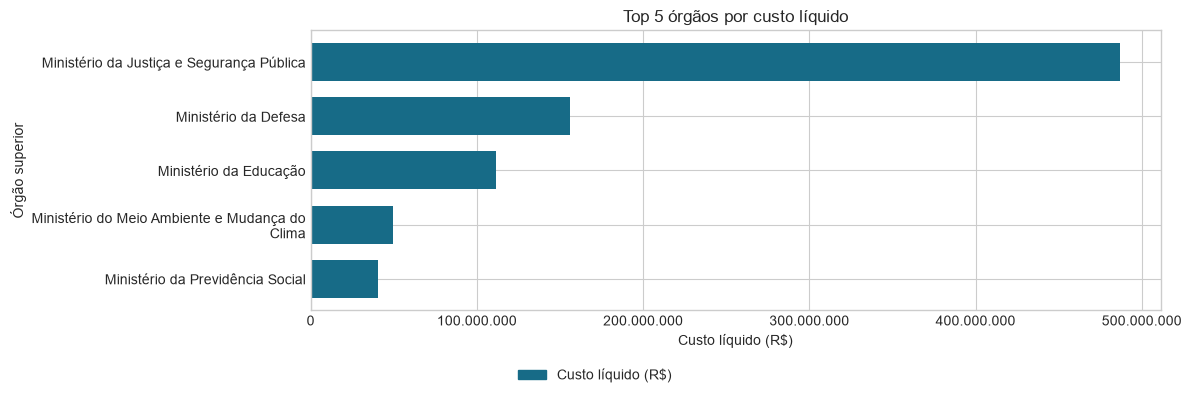

**Evidência:**                            nome_orgao_superior  viagens    custo_total
     Ministério da Justiça e Segurança Pública    75742 486.933.121,65
                          Ministério da Defesa    61912 156.070.304,49
                        Ministério da Educação    65295 111.291.349,34
Ministério do Meio Ambiente e Mudança do Clima    19413  49.697.710,16
              Ministério da Previdência Social     8190  40.417.309,06

In [4]:
df = consultar(
    "SELECT nome_orgao_superior, COUNT(*) AS viagens, SUM(valor_total) AS custo_total\nFROM silver_viagem GROUP BY nome_orgao_superior\nORDER BY custo_total DESC NULLS LAST, nome_orgao_superior LIMIT 5"
)
display(df)
resultados["p1"] = df
grafico(
    df,
    "nome_orgao_superior",
    "custo_total",
    "Top 5 órgãos por custo líquido",
    "Custo líquido (R$)",
    "p1.png",
)
display(Markdown("**Evidência:** " + df.to_string(index=False)))

## 2. Quais são os três destinos com maior custo médio por viagem?

```sql
SELECT destinos, COUNT(*) AS viagens, AVG(valor_total) AS custo_medio
FROM silver_viagem WHERE destinos IS NOT NULL AND valor_total IS NOT NULL
GROUP BY destinos ORDER BY custo_medio DESC, destinos LIMIT 3
```

Empates são ordenados pela dimensão/identificador para resultados reprodutíveis.

**Unidade da comparação:** cada grupo usa o campo `destinos` inteiro, que pode reunir várias cidades. A média é o custo líquido das viagens desse grupo dividido pela quantidade de viagens com custo conhecido. Os resumos não representam cidades isoladas nem a ordem dos deslocamentos. Repetições de localidades são omitidas somente no resumo; o agrupamento SQL permanece integral.

,Referência no gráfico,Localidades (resumo),Viagens,Custo médio por viagem
0,Itinerário 1,"Abu Dabi/Emirados Árabes, Riad/Arábia Saudita, Rio de Janeiro/RJ",1,"R$ 245.852,80"
1,Itinerário 2,"Brasília/DF, Rio Branco/AC, Cruzeiro do Sul/AC, outras localidades",1,"R$ 216.729,36"
2,Itinerário 3,"Brasília/DF, Rio de Janeiro/RJ, Angra dos Reis/RJ, outras localidades",1,"R$ 207.220,14"


**Como interpretar:** Cada grupo contém uma única viagem: a média coincide com o custo dessa viagem. O ranking compara itinerários completos, sem estimar o custo típico de cada cidade. As listas integrais estão em [resultados.json](reports/resultados.json), na seção `p2`.

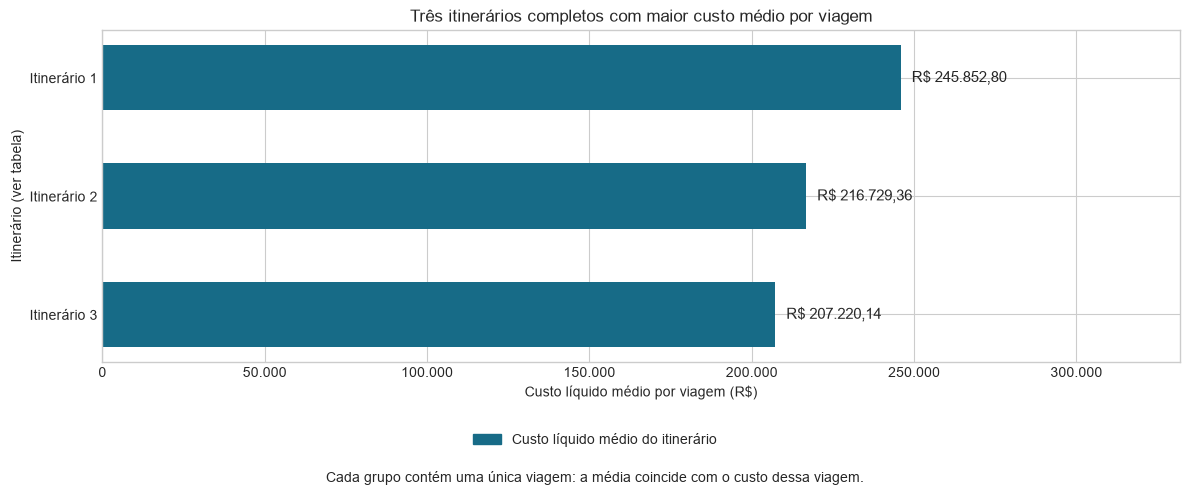

In [5]:
df = consultar('SELECT destinos, COUNT(*) AS viagens, AVG(valor_total) AS custo_medio\nFROM silver_viagem WHERE destinos IS NOT NULL AND valor_total IS NOT NULL\nGROUP BY destinos ORDER BY custo_medio DESC, destinos LIMIT 3')
resultados['p2'] = df
apresentar_destinos(df)


## 3. Qual é a viagem de maior duração e seu custo total?

```sql
SELECT id_viagem, nome_orgao_superior, situacao, data_inicio, data_fim, duracao_dias, valor_total
FROM silver_viagem WHERE duracao_dias IS NOT NULL
ORDER BY duracao_dias DESC, id_viagem LIMIT 1
```

Empates são ordenados pela dimensão/identificador para resultados reprodutíveis.

,id_viagem,nome_orgao_superior,situacao,data_inicio,data_fim,duracao_dias,valor_total
0,0000000000020699856,Ministério da Previdência Social,Realizada,2025-01-13,2026-01-31,384,"0,00"


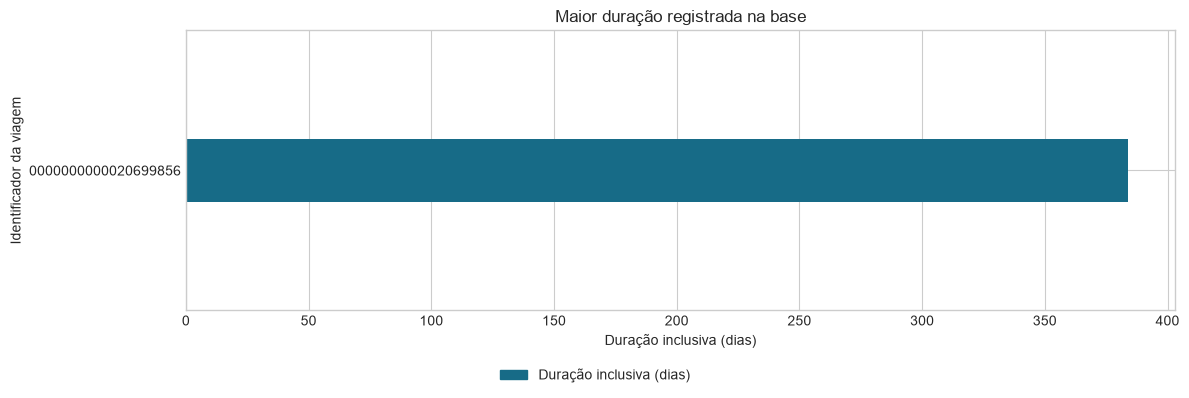

**Evidência:**           id_viagem              nome_orgao_superior  situacao data_inicio   data_fim  duracao_dias  valor_total
0000000000020699856 Ministério da Previdência Social Realizada  2025-01-13 2026-01-31           384         0,00

In [6]:
df = consultar(
    "SELECT id_viagem, nome_orgao_superior, situacao, data_inicio, data_fim, duracao_dias, valor_total\nFROM silver_viagem WHERE duracao_dias IS NOT NULL\nORDER BY duracao_dias DESC, id_viagem LIMIT 1"
)
display(df)
resultados["p3"] = df
grafico(
    df,
    "id_viagem",
    "duracao_dias",
    "Maior duração registrada na base",
    "Duração inclusiva (dias)",
    "p3.png",
)
display(Markdown("**Evidência:** " + df.to_string(index=False)))

## Construção da camada Gold: tabela e VIEW

A VIEW calcula quatro agregações com `JOIN` e `GROUP BY`. A tabela persiste a mesma
fotografia. Cada fato é agregado separadamente, evitando o produto entre pagamentos
e trechos de uma mesma viagem. A tabela deve ser atualizada após nova transformação;
a VIEW reflete imediatamente a Silver.

In [7]:
ddl = (ROOT / "sql" / "3_gold.sql").read_text(encoding="utf-8")
display(Markdown("```sql\n" + ddl + "\n```"))
with conectar() as conexao:
    conexao.execute(ddl)
display(
    consultar("SELECT * FROM gold_metricas ORDER BY metrica, quantidade DESC LIMIT 15")
)
divergencias = consultar(
    "SELECT COUNT(*) AS n FROM ((SELECT * FROM gold_metricas EXCEPT SELECT * FROM vw_gold_metricas) UNION ALL (SELECT * FROM vw_gold_metricas EXCEPT SELECT * FROM gold_metricas)) d"
)
assert int(divergencias.iloc[0]["n"]) == 0, "Tabela Gold divergente da VIEW"

```sql
-- Agregações independentes: não juntar duas relações 1:N na mesma soma.
CREATE OR REPLACE VIEW vw_gold_metricas AS
SELECT 'tipo_pagamento'::text AS metrica,
       p.tipo_pagamento::text AS dimensao,
       COUNT(*)::bigint AS quantidade,
       SUM(p.valor)::numeric AS valor_total,
       AVG(p.valor)::numeric AS valor_medio
FROM silver_viagem v
JOIN silver_pagamento p ON p.id_viagem = v.id_viagem
GROUP BY p.tipo_pagamento
UNION ALL
SELECT 'orgao_pagador', COALESCE(p.nome_orgao_pagador, 'Não informado'),
       COUNT(*), SUM(p.valor), AVG(p.valor)
FROM silver_viagem v
JOIN silver_pagamento p ON p.id_viagem = v.id_viagem
GROUP BY COALESCE(p.nome_orgao_pagador, 'Não informado')
UNION ALL
SELECT 'meio_transporte', COALESCE(t.meio_transporte, 'Não informado'),
       COUNT(*), NULL::numeric, NULL::numeric
FROM silver_viagem v
JOIN silver_trecho t ON t.id_viagem = v.id_viagem
GROUP BY COALESCE(t.meio_transporte, 'Não informado')
UNION ALL
SELECT 'uf_destino', COALESCE(t.destino_uf, 'Não informado'),
       COUNT(*), NULL::numeric, NULL::numeric
FROM silver_viagem v
JOIN silver_trecho t ON t.id_viagem = v.id_viagem
GROUP BY COALESCE(t.destino_uf, 'Não informado');

CREATE TABLE IF NOT EXISTS gold_metricas (
    metrica TEXT NOT NULL,
    dimensao TEXT NOT NULL,
    quantidade BIGINT NOT NULL,
    valor_total NUMERIC,
    valor_medio NUMERIC,
    PRIMARY KEY (metrica, dimensao)
);
TRUNCATE gold_metricas;
INSERT INTO gold_metricas SELECT * FROM vw_gold_metricas;

```

,metrica,dimensao,quantidade,valor_total,valor_medio
0,meio_transporte,Veículo Oficial,386424,NaN,NaN
1,meio_transporte,Aéreo,232666,NaN,NaN
2,meio_transporte,Rodoviário,64970,NaN,NaN
3,meio_transporte,Veículo Próprio,42846,NaN,NaN
4,meio_transporte,Inválido,26659,NaN,NaN
5,meio_transporte,Fluvial,8429,NaN,NaN
6,meio_transporte,Ferroviário,874,NaN,NaN
7,meio_transporte,Marítimo,481,NaN,NaN
8,orgao_pagador,Sigiloso,86878,"170.659.883,35","1.964,36"
9,orgao_pagador,Fundo Nacional de Segurança Pública,53440,"141.911.719,64","2.655,53"


## 4. Qual é o tipo de pagamento com maior valor médio?

```sql
SELECT dimensao AS tipo_pagamento, quantidade, valor_medio FROM gold_metricas WHERE metrica='tipo_pagamento' ORDER BY valor_medio DESC NULLS LAST, dimensao
```

A tabela ordena os rótulos publicados na fonte. Marcadores de sigilo ou de classificação ausente são interpretados separadamente na síntese.

,tipo_pagamento,quantidade,valor_medio
0,PASSAGEM,186008,"1.856,78"
1,DIÁRIAS,366351,"1.797,55"
2,Serviço correlato: seguro,4882,"447,72"
3,RESTITUIÇÃO,11570,"245,69"


**Liderança observada:** tipo_pagamento  quantidade  valor_medio
      PASSAGEM      186008     1.856,78

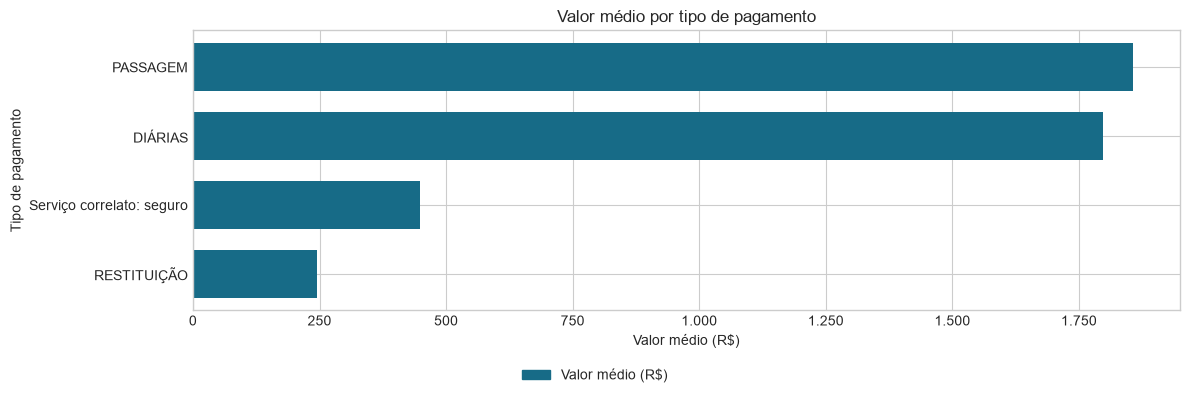

In [8]:
df = consultar(
    "SELECT dimensao AS tipo_pagamento, quantidade, valor_medio FROM gold_metricas WHERE metrica='tipo_pagamento' ORDER BY valor_medio DESC NULLS LAST, dimensao"
)
display(df)
resultados["p4"] = df
display(Markdown("**Liderança observada:** " + df.head(1).to_string(index=False)))
grafico(
    df.head(10),
    "tipo_pagamento",
    "valor_medio",
    "Valor médio por tipo de pagamento",
    "Valor médio (R$)",
    "p4.png",
)

## 5. Qual é o meio de transporte mais usado nos trechos?

```sql
SELECT dimensao AS meio_transporte, quantidade FROM gold_metricas WHERE metrica='meio_transporte' ORDER BY quantidade DESC, dimensao
```

A tabela ordena os rótulos publicados na fonte. Marcadores de sigilo ou de classificação ausente são interpretados separadamente na síntese.

,meio_transporte,quantidade
0,Veículo Oficial,386424
1,Aéreo,232666
2,Rodoviário,64970
3,Veículo Próprio,42846
4,Inválido,26659
5,Fluvial,8429
6,Ferroviário,874
7,Marítimo,481


**Liderança observada:** meio_transporte  quantidade
Veículo Oficial      386424

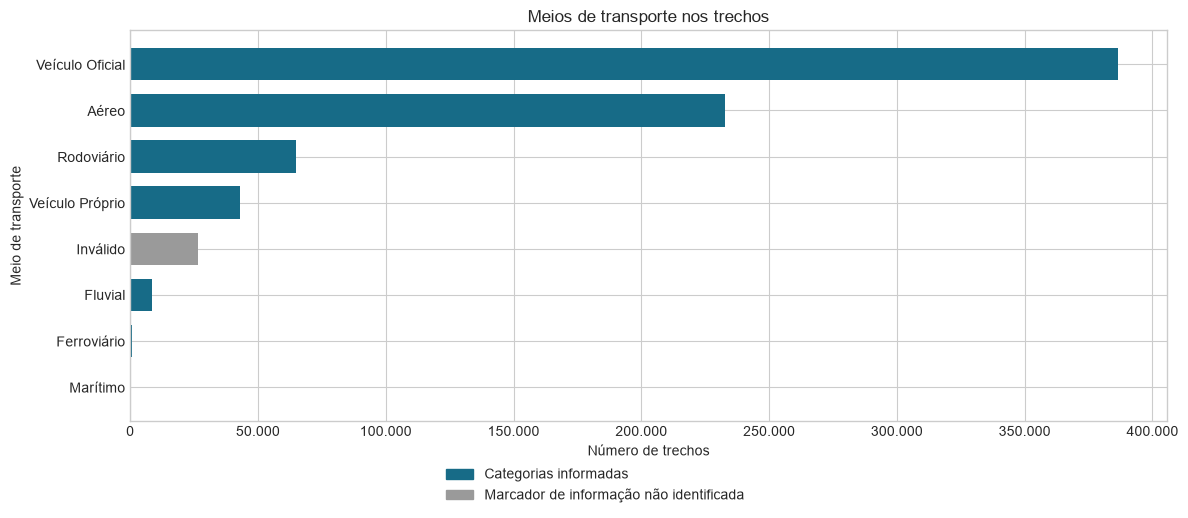

In [9]:
df = consultar(
    "SELECT dimensao AS meio_transporte, quantidade FROM gold_metricas WHERE metrica='meio_transporte' ORDER BY quantidade DESC, dimensao"
)
display(df)
resultados["p5"] = df
display(Markdown("**Liderança observada:** " + df.head(1).to_string(index=False)))
grafico(
    df.head(10),
    "meio_transporte",
    "quantidade",
    "Meios de transporte nos trechos",
    "Número de trechos",
    "p5.png",
)

## 6. Qual UF de destino aparece em mais trechos?

```sql
SELECT dimensao AS uf_destino, quantidade FROM gold_metricas WHERE metrica='uf_destino' ORDER BY quantidade DESC, dimensao
```

A tabela ordena os rótulos publicados na fonte. Marcadores de sigilo ou de classificação ausente são interpretados separadamente na síntese.

,uf_destino,quantidade
0,São Paulo,82722
1,Distrito Federal,79962
2,Minas Gerais,50965
3,Rio de Janeiro,44197
4,Paraná,42603
5,Pará,40044
6,Rio Grande do Sul,38684
7,Mato Grosso do Sul,30516
8,Bahia,28375
9,Pernambuco,28372


**Liderança observada:** uf_destino  quantidade
 São Paulo       82722

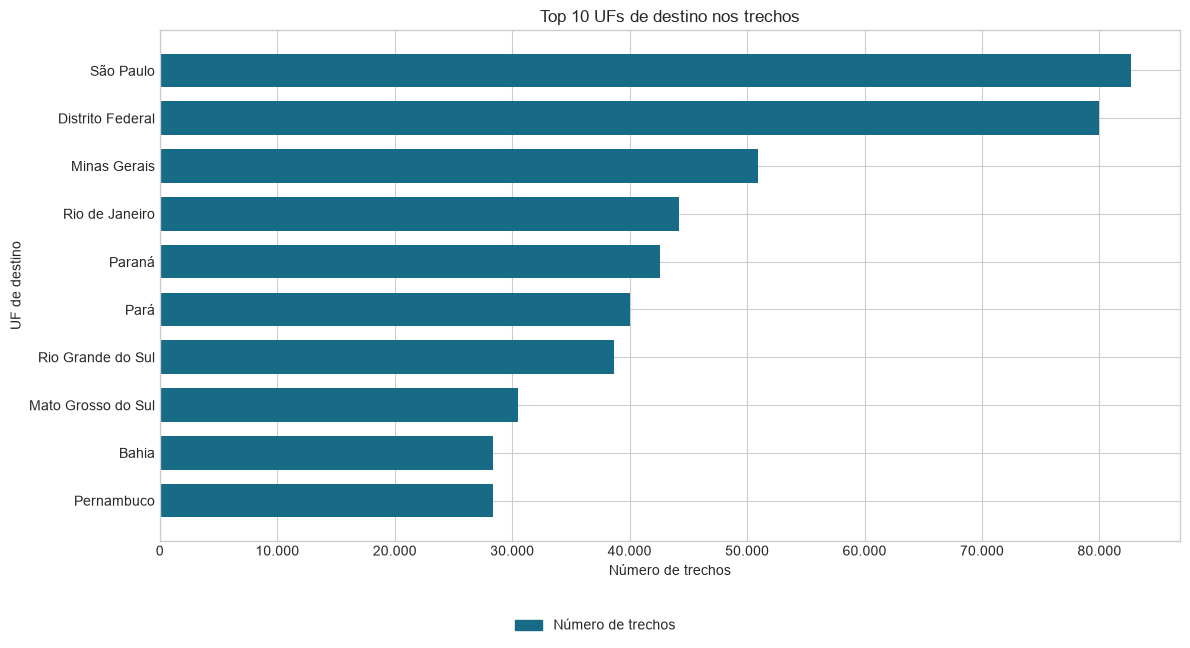

In [10]:
df = consultar(
    "SELECT dimensao AS uf_destino, quantidade FROM gold_metricas WHERE metrica='uf_destino' ORDER BY quantidade DESC, dimensao"
)
display(df)
resultados["p6"] = df
display(Markdown("**Liderança observada:** " + df.head(1).to_string(index=False)))
grafico(
    df.head(10),
    "uf_destino",
    "quantidade",
    "Top 10 UFs de destino nos trechos",
    "Número de trechos",
    "p6.png",
)

## 7. Qual órgão pagou mais no total?

```sql
SELECT dimensao AS orgao_pagador, quantidade AS pagamentos, valor_total FROM gold_metricas WHERE metrica='orgao_pagador' ORDER BY valor_total DESC NULLS LAST, dimensao LIMIT 10
```

A tabela ordena os rótulos publicados na fonte. Marcadores de sigilo ou de classificação ausente são interpretados separadamente na síntese.

In [11]:
df = consultar(
    "SELECT dimensao AS orgao_pagador, quantidade AS pagamentos, valor_total FROM gold_metricas WHERE metrica='orgao_pagador' ORDER BY valor_total DESC NULLS LAST, dimensao LIMIT 10"
)
display(df)
resultados["p7"] = df
display(Markdown("**Liderança observada:** " + df.head(1).to_string(index=False)))

,orgao_pagador,pagamentos,valor_total
0,Sigiloso,86878,"170.659.883,35"
1,Fundo Nacional de Segurança Pública,53440,"141.911.719,64"
2,Comando da Aeronáutica,45962,"81.180.823,06"
3,Comando do Exército,22056,"35.901.379,45"
4,Instituto Nacional do Seguro Social,17899,"35.385.354,57"
5,Ministério da Gestão e da Inovação em Serviços Públicos - Unidades com vínculo direto,20136,"34.640.016,36"
6,Instituto Brasileiro do Meio Ambiente e dos Recursos Naturais Renováveis,16581,"31.010.870,85"
7,Ministério das Relações Exteriores - Unidades com vínculo direto,3685,"25.589.924,60"
8,Receita Federal do Brasil,18833,"23.548.336,51"
9,Ministério da Agricultura e Pecuária - Unidades com vínculo direto,15757,"22.343.023,69"


**Liderança observada:** orgao_pagador  pagamentos    valor_total
     Sigiloso       86878 170.659.883,35

**Limite de identificação:** `Sigiloso` é um rótulo de divulgação, e não o nome de um órgão. O total dessa categoria não permite identificar um pagador único. A síntese também apresenta o maior órgão cujo nome foi divulgado.

## Interpretação e limites

O ranking de custos indica concentração dos gastos, não irregularidade. O ranking
de custo médio deve ser lido junto à quantidade de viagens: um itinerário com uma
única observação não representa um padrão estável. A viagem mais longa merece
verificação de contexto, sem presumir erro. Contagem de trechos mede movimentação,
não pessoas distintas. Pagamentos e custo líquido da viagem têm conceitos diferentes
e não devem ser somados entre si.

Antes da entrega, conferir rejeições e a cobertura temporal; a interpretação vale
somente para o recorte fornecido e os registros aceitos. Uma evolução seria medir
custo por diária e por órgão, controlar viagens internacionais e adicionar séries mensais.


In [12]:
saida = ROOT / "reports" / "resultados.json"
saida.parent.mkdir(parents=True, exist_ok=True)
saida.write_text(
    json.dumps(
        {
            k: json.loads(
                v.to_json(orient="records", date_format="iso", force_ascii=False)
            )
            for k, v in resultados.items()
        },
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)
engine.dispose()

## Síntese dos resultados
Indicadores calculados a partir das consultas anteriores, com ressalvas de interpretação.

In [13]:
def reais(valor):
    if pd.isna(valor):
        return 'Não informado'
    return f'R$ {float(valor):,.2f}'.replace(',', '_').replace('.', ',').replace('_', '.')

total_viagens = float(consultar('SELECT SUM(valor_total) AS total FROM silver_viagem').iloc[0]['total'])
total_pago = float(consultar('SELECT SUM(valor) AS total FROM silver_pagamento').iloc[0]['total'])
total_trechos = int(consultar('SELECT COUNT(*) AS total FROM silver_trecho').iloc[0]['total'])
p1, p2, p3, p4, p5, p6, p7 = [resultados[f'p{i}'] for i in range(1, 8)]
nao_identificados = {'sigiloso', 'não informado', 'inválido'}
nomeados = p7[~p7['orgao_pagador'].str.strip().str.casefold().isin(nao_identificados)]
primeiro = p7.iloc[0]
if primeiro['orgao_pagador'].strip().casefold() in nao_identificados:
    texto_pagador = f"O maior agrupamento por rótulo é {primeiro['orgao_pagador']}, com {reais(primeiro['valor_total'])} ({float(primeiro['valor_total']) / total_pago:.1%} dos pagamentos aceitos). Esse rótulo não identifica um órgão único."
else:
    texto_pagador = f"O órgão pagador {primeiro['orgao_pagador']} lidera com {reais(primeiro['valor_total'])}."
if not nomeados.empty:
    identificado = nomeados.iloc[0]
    texto_pagador += f" Entre os órgãos com nome divulgado, {identificado['orgao_pagador']} lidera com {reais(identificado['valor_total'])}."
situacao = p3.iloc[0]['situacao']
qualidade = consultar("SELECT metrica, dimensao, quantidade, valor_total FROM gold_metricas WHERE lower(dimensao) IN ('inválido', 'não informado', 'sigiloso') ORDER BY metrica, dimensao")
linhas = [
    f"Os cinco órgãos líderes concentram {float(p1['custo_total'].sum()) / total_viagens:.1%} do custo líquido conhecido. {p1.iloc[0]['nome_orgao_superior']} lidera com {reais(p1.iloc[0]['custo_total'])}. Isso mede concentração, sem demonstrar irregularidade.",
    f"O itinerário com maior média registra {reais(p2.iloc[0]['custo_medio'])}. Quantidade de viagens nesse itinerário: {int(p2.iloc[0]['viagens'])}. O ranking compara itinerários completos, não cidades isoladas. " + ('Os três grupos possuem uma viagem cada; suas médias coincidem com os custos individuais dessas viagens. ' if p2['viagens'].eq(1).all() else '') + 'Médias com poucas observações devem ser interpretadas com cautela; esse ranking não estima o custo típico de uma cidade.',
    f"A viagem {p3.iloc[0]['id_viagem']} apresenta período informado de {int(p3.iloc[0]['duracao_dias'])} dias inclusivos e custo líquido registrado de {reais(p3.iloc[0]['valor_total'])}. Situação: {situacao if pd.notna(situacao) else 'não informada'}. O valor zero registrado e o período informado não comprovam, isoladamente, despesa efetiva nula ou deslocamento contínuo durante todo o intervalo.",
    f"O tipo {p4.iloc[0]['tipo_pagamento']} tem o maior valor médio: {reais(p4.iloc[0]['valor_medio'])}. A média é por registro de pagamento, não por viagem.",
    f"O meio {p5.iloc[0]['meio_transporte']} representa {int(p5.iloc[0]['quantidade']) / total_trechos:.1%} dos trechos aceitos. Isso mede segmentos de deslocamento, não pessoas distintas.",
    f"A UF de destino {p6.iloc[0]['uf_destino']} aparece em {int(p6.iloc[0]['quantidade'])} trechos ({int(p6.iloc[0]['quantidade']) / total_trechos:.1%} do total). O ranking indica concentração operacional de destinos.",
    texto_pagador,
    'A fonte contém marcadores de classificação ausente ou inválida em campos textuais. Eles são preservados para rastreabilidade, mas não representam modalidades de transporte, UFs ou órgãos identificáveis. Sua frequência está discriminada na tabela de qualidade. Custo líquido da viagem e total de pagamentos são perspectivas diferentes e não devem ser somados entre si.'
]
sintese = '\n\n'.join(linhas)
display(Markdown(sintese))
display(qualidade)
(ROOT / 'reports' / 'insights.md').write_text(sintese, encoding='utf-8')
(ROOT / 'reports' / 'qualidade_categorias.json').write_text(qualidade.to_json(orient='records', force_ascii=False, indent=2), encoding='utf-8')
engine.dispose()


Os cinco órgãos líderes concentram 71.1% do custo líquido conhecido. Ministério da Justiça e Segurança Pública lidera com R$ 486.933.121,65. Isso mede concentração, sem demonstrar irregularidade.

O itinerário com maior média registra R$ 245.852,80. Quantidade de viagens nesse itinerário: 1. O ranking compara itinerários completos, não cidades isoladas. Os três grupos possuem uma viagem cada; suas médias coincidem com os custos individuais dessas viagens. Médias com poucas observações devem ser interpretadas com cautela; esse ranking não estima o custo típico de uma cidade.

A viagem 0000000000020699856 apresenta período informado de 384 dias inclusivos e custo líquido registrado de R$ 0,00. Situação: Realizada. O valor zero registrado e o período informado não comprovam, isoladamente, despesa efetiva nula ou deslocamento contínuo durante todo o intervalo.

O tipo PASSAGEM tem o maior valor médio: R$ 1.856,78. A média é por registro de pagamento, não por viagem.

O meio Veículo Oficial representa 50.6% dos trechos aceitos. Isso mede segmentos de deslocamento, não pessoas distintas.

A UF de destino São Paulo aparece em 82722 trechos (10.8% do total). O ranking indica concentração operacional de destinos.

O maior agrupamento por rótulo é Sigiloso, com R$ 170.659.883,35 (16.9% dos pagamentos aceitos). Esse rótulo não identifica um órgão único. Entre os órgãos com nome divulgado, Fundo Nacional de Segurança Pública lidera com R$ 141.911.719,64.

A fonte contém marcadores de classificação ausente ou inválida em campos textuais. Eles são preservados para rastreabilidade, mas não representam modalidades de transporte, UFs ou órgãos identificáveis. Sua frequência está discriminada na tabela de qualidade. Custo líquido da viagem e total de pagamentos são perspectivas diferentes e não devem ser somados entre si.

,metrica,dimensao,quantidade,valor_total
0,meio_transporte,Inválido,26659,NaN
1,orgao_pagador,Sigiloso,86878,"170.659.883,35"
2,uf_destino,Inválido,29,NaN
3,uf_destino,Não informado,14742,NaN
